# ABAP: from BirdMap to an atlas dataset

Download BirdMap observations, prepare linked tables, and explore a real Kenya snapshot. Install the environment with `uv sync --frozen`; raw data and the eBird 2026 taxonomy are supplied separately.

## The workflow

The ABAP path runs from BirdMap through download and preparation to the green dataset. Blue is source data, orange is curated taxonomy, purple is processing, and green is output. The diagram is the same one used in the project README.

```mermaid
flowchart LR
    EBD[/eBird Basic Dataset<br/>species observations/] --> EP(eBird preparation)
    PROJECT[/eBird project export/] --> EP
    API([BirdMap API]) --> DOWNLOAD(ABAP download)
    DOWNLOAD --> RAW[/Downloaded ABAP snapshot/]
    RAW --> AP(ABAP preparation)
    SUPPLIED[/Supplied ABAP export<br/>adapter pending/] -.-> AP
    TAX[/eBird taxonomy<br/>declared version and provenance/] --> EP
    TAX --> AP
    CROSS[/Curated ABAP crosswalk<br/>and regional decisions/] --> AP
    PENTAD[[Shared pentad functions]] -.-> EP
    PENTAD -.-> AP
    EP --> E[(Prepared eBird dataset)]
    AP --> A[(Prepared ABAP dataset)]
    E --> COMBINE(Combine datasets)
    A --> COMBINE
    COMBINE --> C[(Combined dataset<br/>compatible taxonomy provenance)]

    classDef external fill:#e5effa,stroke:#356796,color:#153e62
    classDef curated fill:#fff0d2,stroke:#976a10,color:#583900
    classDef process fill:#e9e5f6,stroke:#6553a0,color:#352961
    classDef utility fill:#f1f1f1,stroke:#666,color:#222
    classDef output fill:#dff2e8,stroke:#287a50,color:#164a2f
    class EBD,PROJECT,API,RAW,SUPPLIED,TAX external
    class CROSS curated
    class DOWNLOAD,EP,AP,COMBINE process
    class PENTAD utility
    class E,A,C output
```

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd() if (Path.cwd() / 'bird_atlas').is_dir() else Path.cwd().parent
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Get a snapshot

The example uses an existing Kenya snapshot (23 July 2007–3 November 2026). Set `download = True` for a small new download; omit the dates in the command to request all available history. Dates select checklist start dates, and the API provides detections rather than non-detections.

In [2]:
download = False
country, start, end = 'kenya', '2024-01-01', '2024-01-31'
download_dir = root / 'data/raw/abap/downloaded'
snapshot = root / 'data/raw/abap/downloaded/kenya_2007-07-23_2026-11-03'

if download:
    subprocess.run([sys.executable, str(root / 'scripts/abap/download_abap.py'),
                    '--country', country, '--start-date', start, '--end-date', end,
                    '--output-dir', str(download_dir)], cwd=root, check=True)
    snapshot = download_dir / f'{country}_{start}_{end}'

print('Snapshot:', snapshot.relative_to(root))

Snapshot: data/raw/abap/downloaded/kenya_2007-07-23_2026-11-03


## 2. Prepare the tables

Preparation reconciles overlapping full-protocol and ad-hoc cards, links their detections to species, and writes the dataset to a temporary folder. To keep it, set `output` to a new folder under `data/prepared/`. The `kenya` region selects taxonomy decisions; it does not filter observations geographically.

In [3]:
temporary = tempfile.TemporaryDirectory(prefix='bird-atlas-abap-')
output = Path(temporary.name) / 'prepared'
taxonomy = root / 'data/taxonomy/ebird_2026.csv'
result = subprocess.run([sys.executable, str(root / 'scripts/abap/prepare.py'),
                '--snapshot', str(snapshot), '--output-dir', str(output),
                '--taxonomy', str(taxonomy), '--region', 'kenya'], cwd=root, check=True, capture_output=True, text=True)
print(result.stdout)

Snapshot: data/raw/abap/downloaded/kenya_2007-07-23_2026-11-03
Taxonomic region: kenya (not a spatial filter)
Output: /var/folders/cm/dh8lmmxn3b5bcb2_gbz16ycm0000gn/T/bird-atlas-abap-m957tk5s/prepared
Records: 1,302,780; cards: 61,116; pentads: 2,635; source species codes: 1,126; resolved taxa: 1,105; unresolved records: 0
Source protocols before deduplication: adhoc: 585,599, full_protocol: 717,585
Card overlaps: 9; merged: 9; duplicate detections removed: 404



In [4]:
result = subprocess.run([sys.executable, str(root / 'scripts/shared/validate.py'), str(output)], cwd=root, check=True, capture_output=True, text=True)
print(result.stdout)

Valid shared keys: 61116 cards, 1302780 records, 1105 taxa.



## 3. Explore coverage

Each point is a pentad, colored by card count. This shows where and when checklists were submitted, not bird abundance. The first and last years may be partial; the snapshot ends on 3 November 2026.

/var/folders/cm/dh8lmmxn3b5bcb2_gbz16ycm0000gn/T/ipykernel_74410/1500312663.py:1: DtypeWarning: Columns (9: observer_name, 10: unparsed_start_time) have mixed types. Specify dtype option on import or set low_memory=False.
  cards = pd.read_csv(output / 'cards.csv', dtype={'pentad_id': str})


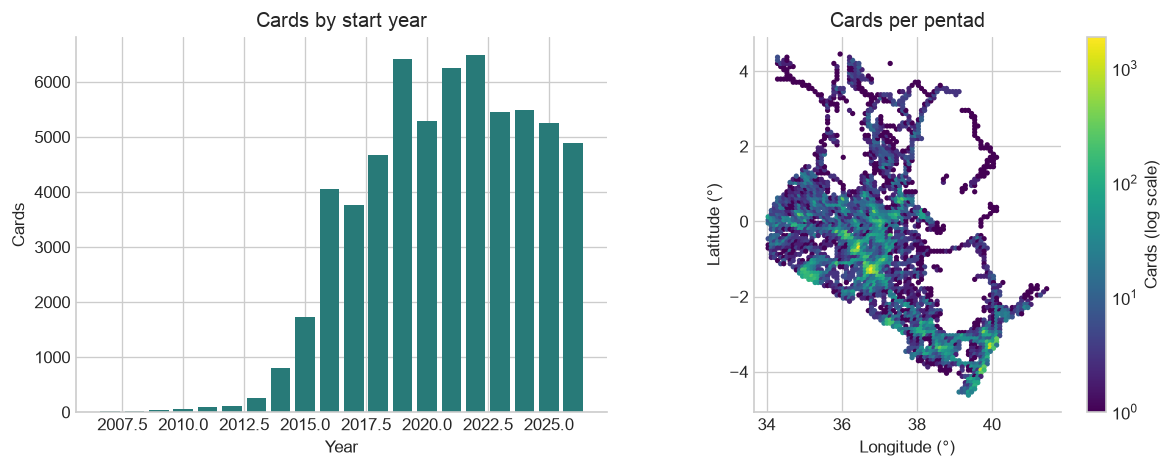

In [5]:
cards = pd.read_csv(output / 'cards.csv', dtype={'pentad_id': str})
pentads = pd.read_csv(output / 'pentads.csv', dtype={'pentad_id': str})
annual = pd.to_datetime(cards['start_date']).dt.year.value_counts().sort_index()
coverage = cards.groupby('pentad_id').size().rename('cards').reset_index().merge(pentads, on='pentad_id')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(annual.index, annual.values, color='#287a78')
axes[0].set(title='Cards by start year', xlabel='Year', ylabel='Cards')
points = axes[1].scatter(coverage['longitude'], coverage['latitude'], c=coverage['cards'],
                         s=10, cmap='viridis', norm=plt.matplotlib.colors.LogNorm(), linewidths=0)
axes[1].set(title='Cards per pentad', xlabel='Longitude (°)', ylabel='Latitude (°)', aspect='equal')
fig.colorbar(points, ax=axes[1], label='Cards (log scale)')
fig.tight_layout()

## 4. Follow a species into the output

BirdMap's species codes are matched through a curated crosswalk to the eBird reference. The example below follows one actual detection into `species.csv`; `records.csv.gz` retains both identifiers. An exact match does not verify field identification. Review unresolved and provisional mappings in `audit.csv`.

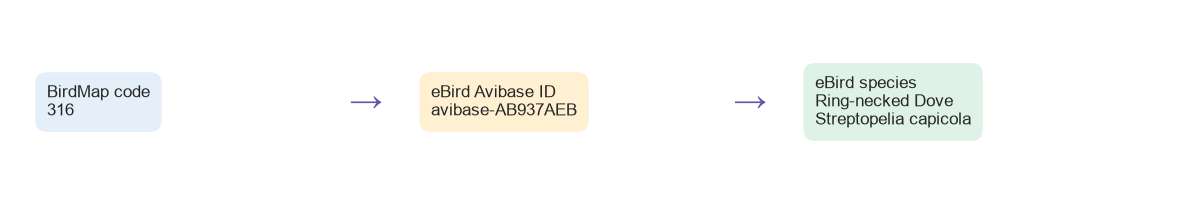

In [6]:
records = pd.read_csv(output / 'records.csv.gz', usecols=['source_spp', 'ebird_avibase_id', 'taxonomy_status'], dtype=str)
species = pd.read_csv(output / 'species.csv', dtype=str)
example = records[records['taxonomy_status'].eq('exact')].merge(species, on='ebird_avibase_id').iloc[0]
fig, ax = plt.subplots(figsize=(10, 1.8))
ax.axis('off')
for x, title, value, color in [(0.03, 'BirdMap code', example['source_spp'], '#e5effa'),
                                (0.36, 'eBird Avibase ID', example['ebird_avibase_id'], '#fff0d2'),
                                (0.69, 'eBird species', example['common_name'] + "\n" + example['scientific_name'], '#dff2e8')]:
    ax.text(x, 0.5, f'{title}\n{value}', transform=ax.transAxes, va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.7', facecolor=color, edgecolor='none'))
ax.text(0.29, 0.5, '→', transform=ax.transAxes, fontsize=20, va='center', color='#6553a0')
ax.text(0.62, 0.5, '→', transform=ax.transAxes, fontsize=20, va='center', color='#6553a0')
fig.tight_layout()

## The files you can use

`cards.csv` describes checklists; `records.csv.gz` links each detection to its `card_id` and `ebird_avibase_id`; `species.csv` gives species names; `pentads.csv` describes locations. Observer IDs are JSON lists. The audit and manifest retain mapping decisions and provenance.